# 02 - Exploratory date Analysis (EDA)

## objective

perform a analysis Exploratória of date with the objective of understand the comportamento of the variables of the set of date, identificar patterns, relationships, possible inconsistencies and gerar evidências that subsidiem the stages of preparação of the date and modeling preditiva.

## questions that desejamos answer

Throughout this step, we seek to answer:

- the are distribuídas the variables numeric?
- there are values extremos (*outliers*)?
- the distributions apresentam assimetria?
- there are correlation entre the variables numeric?

In [1]:
from pathlib import Path
import pandas as pd

# Caminho of the projeto
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "interm"

# Carregamento of the date
csv_file = DATA_PATH / "data_1.csv"
banco = pd.read_csv(csv_file)

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Parâmetros of estilo of the Gráfico based in the manual of the MBA
plt.rcParams.update({

    # font
    "font.family": "Arial",
    "font.size": 11,

    # background
    "figure.facecolor": "white",
    "axes.facecolor": "white",

    # without grid
    "axes.grid": False,

    # without title
    "axes.titlesize": 0,

    # axes
    "axes.edgecolor": "black",
    "axes.linewidth": 1.5,

    # color of the textos
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",

    # size of the titles of the axes
    "axes.labelsize": 11

})

In [3]:
# dimension of the dataset
n_samples, n_features = banco.shape

print("=" * 35)
print("dimension of the DATASET")
print("=" * 35)
print(f"Número de observações : {n_samples}")
print(f"Número de atributos   : {n_features}")

DIMENSÃO DO DATASET
Número de observações : 19634
Número de atributos   : 9


## analyses statistics descriptive

In [4]:
banco.describe()

,id_produto,valor_unitario,quantidade,valor_total,preco_custo,saldo
count,19634.000000,19634.000000,19634.000000,19634.000000,8458.000000,8932.000000
mean,218.267342,72.463404,4.183559,96.755103,69.029558,46.740596
std,167.363054,172.379914,12.511824,244.465625,291.181147,242.768560
min,0.000000,0.500000,1.000000,1.000000,0.000000,-14179.000000
25%,44.000000,5.000000,1.000000,16.000000,15.000000,13.000000
50%,233.000000,35.000000,1.000000,44.000000,25.000000,25.000000
75%,318.000000,70.000000,2.000000,90.000000,70.000000,40.000000
max,737.000000,7536.000000,400.000000,9720.000000,17160.000000,7560.000000


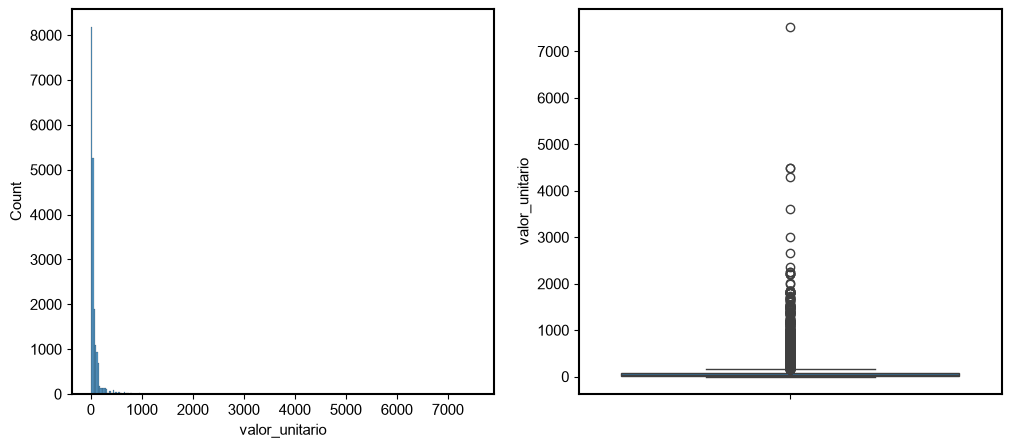

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,5))

sns.histplot(data=banco['valor_unitario'], ax=axes[0])
sns.boxplot(data=banco['valor_unitario'], ax=axes[1])

plt.show()

In [6]:
print(f'A variável valor_unitario possui skweness de {banco['valor_unitario'].skew()}')
print(f'A variável valor_unitario possui curtose de {banco['valor_unitario'].kurt()}')

A variável valor_unitario possui skweness de 11.841857154816461
A variável valor_unitario possui curtose de 291.0026894425543


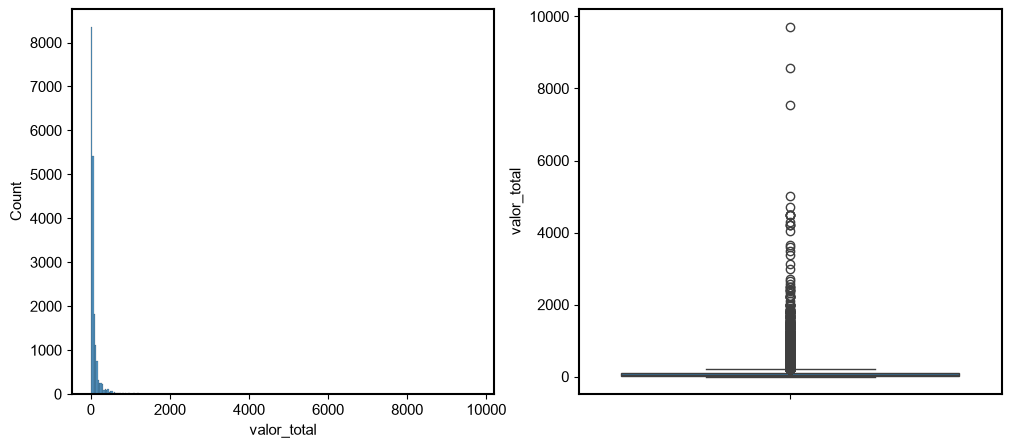

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12,5))

sns.histplot(data=banco['valor_total'], ax=axes[0])
sns.boxplot(data=banco['valor_total'], ax=axes[1])

plt.show()

In [8]:
print(f'A variável valor_total possui skweness de {banco['valor_total'].skew()}')
print(f'A variável valor_total possui curtose de {banco['valor_total'].kurt()}')

A variável valor_total possui skweness de 13.408669647390148
A variável valor_total possui curtose de 325.4776208575693


we note that a distribution of the variables `value_unitario` and `value_total` are assimétricas positivas, this is, are assimétricas direita. this fica evidenciado pelas medidas of *skewness* positivas. also disso, the values of the *curtose* indicam a cauda longa and pesada, the that is a result direto of few products possuirem values high, the that does the that a mean fique acima of the mediana.

Este result traz a perspectiva: which **products** and **groups** alteram tanto esses values? the eles must be tratados?
* Veja that not necessariamente esses high values are *outliers*, because can be sales possible and consistentes.
* there is a relevance in the type of product (group) sold that altere the revenue?

### Identificando outliers

#### value Unitário

In [9]:
banco.groupby('grupo')['valor_unitario'].describe()

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
ANTENA,4270.0,63.516604,119.833575,5.0,40.00,50.0,60.00,4500.0
CABO,4779.0,2.483346,9.171108,0.5,1.00,1.5,2.00,450.0
COMPONENTES ANTENAS,3122.0,39.593370,104.790107,1.0,10.00,20.0,40.00,3600.0
CONVERSOR,1327.0,102.328561,32.060872,20.0,90.00,100.0,120.00,250.0
INTERFONE,382.0,239.836387,273.561337,1.0,68.25,180.0,290.00,2650.0
PORTAO,1363.0,185.249315,336.421505,2.5,40.00,65.0,130.00,2350.0
PRODUTO ESPECIAL,153.0,228.935294,648.406994,0.8,30.00,55.0,245.00,7536.0
RECEPTOR,199.0,350.670854,131.493791,75.0,265.00,330.0,450.00,964.0
REDES,5.0,206.000000,98.386991,100.0,100.00,250.0,280.00,300.0


In [10]:
banco.loc[
    banco['valor_unitario'] > 1000,
    ['grupo','descricao','valor_unitario','quantidade','valor_total']
].sort_values('valor_unitario', ascending=False)

,grupo,descricao,valor_unitario,quantidade,valor_total
1127,PRODUTO ESPECIAL,PAGAMENTO 1 PARCELA,7536.0,1.0,7536.0
16536,ANTENA,MINI REPETIDOR DE SINAL CELULAR AQUARIO 60,4500.0,1.0,4500.0
14478,ANTENA,MINI REPETIDOR DE SINAL CELULAR AQUARIO 60,4500.0,1.0,4500.0
1528,SEM GRUPO,REPETIDOR DE SINAL CELULAR 800 MHZ 70DB RP 870,4300.0,1.0,4300.0
1770,COMPONENTES ANTENAS,"MODULADOR ADJACENTE 19"" 4M 120",3600.0,1.0,3600.0
...,...,...,...,...,...
7773,PORTAO,MOTOR 1.5MT BV CONDOMINIUM JETFLEX,1050.0,1.0,1050.0
16608,PORTAO,"MOTOR 1/3HP 8S 1,40MT PPA",1050.0,1.0,1050.0
17684,PORTAO,"MOTOR 1/3HP 8S 1,40MT GAREN",1050.0,1.0,1050.0
18934,PORTAO,CENTRAL COLETIVA COLLECTIVE 12,1050.0,1.0,1050.0


we note that a variability of products vendidos nesta company is very large, the that resulta in a discrepância in the values of sale. there are itens vendidos that vão very also of the mean of the values of sale performed dentro of the group, mas this not torna the sales inconsistentes. Esta analysis evidencia a necessidade of outra abordagem: the revenue global must be considerado the a analysis of forecasting, of maneira that whether possible acompanhar the growth seasonal throughout of the years.

a oportunidade interesting is analyze the revenue by group separadamente for understand more afundo the negócio.

#### quantity

In [11]:
banco.groupby('grupo')['quantidade'].describe()

,count,mean,std,min,25%,50%,75%,max
grupo,,,,,,,,
ANTENA,4270.0,1.081030,1.441282,1.0,1.0,1.0,1.0,93.0
CABO,4779.0,10.454907,20.727411,1.0,2.0,5.0,10.0,400.0
COMPONENTES ANTENAS,3122.0,1.263293,1.724874,1.0,1.0,1.0,1.0,50.0
CONVERSOR,1327.0,1.088169,0.400494,1.0,1.0,1.0,1.0,7.0
INTERFONE,382.0,2.887435,5.812955,1.0,1.0,1.0,1.0,50.0
PORTAO,1363.0,1.231108,0.848338,1.0,1.0,1.0,1.0,14.0
PRODUTO ESPECIAL,153.0,1.980392,4.626114,1.0,1.0,1.0,1.0,50.0
RECEPTOR,199.0,1.376884,1.051054,1.0,1.0,1.0,1.0,10.0
REDES,5.0,1.000000,0.000000,1.0,1.0,1.0,1.0,1.0


In [12]:
banco.loc[
    banco['quantidade'] > 50,
    ['grupo','descricao','quantidade','valor_unitario','valor_total']
].sort_values('quantidade', ascending=False)

,grupo,descricao,quantidade,valor_unitario,valor_total
12894,CABO,CABO COAXIAL RG 59,400.0,2.0,680.0
13130,CABO,CABO COAXIAL RG 59,400.0,2.0,680.0
10465,CABO,CONECTOR F COMPRESSAO PROFISSIONAL RG59 /,400.0,2.7,1080.0
5877,CABO,MC CABO COAXIAL 06 67% 100M BR,350.0,1.5,455.0
12893,CABO,CONECTOR ROSCA,350.0,1.0,350.0
...,...,...,...,...,...
15424,SEGURANCA,SUPORTE P/ CONCERTINA V 30CM,55.0,10.0,550.0
18712,SEGURANCA,CABO DE ACO,55.0,2.2,121.0
18345,SEGURANCA,CABO DE ACO,55.0,2.2,121.0
18957,CABO,CABO COAXIAL RG 59,55.0,2.5,137.5


Esta analysis traz a evidencia more interesting a respeito of the market of sales desta company, because there are a high variability in the type of product sold and a forma the ela is sold. there are products that with only a único item sold resulta in high revenue, mas to the mesmo tempo there are products vendidos by unit and/or metragem that not garante a high revenue, because the value aggregated to the product is low.

therefore, of maneira geral, there are in the significant outliers, the sales are legitimate and consistentes. however, there are groups that can apresentar discrepâncias, the without group, product ESPECIAL, TV BOX and REDES, mas that it is useful analyze sua contribuição for the revenue.

## distribution by group

In [13]:
banco['grupo'].value_counts()

grupo
CABO                   4779
ANTENA                 4270
COMPONENTES ANTENAS    3122
SEGURANCA              1406
PORTAO                 1363
CONVERSOR              1327
SUPORTE TELEVISÃO      1309
SEM GRUPO              1150
INTERFONE               382
RECEPTOR                199
TV BOX                  169
PRODUTO ESPECIAL        153
REDES                     5
Name: count, dtype: int64

In [14]:
banco['grupo'].value_counts(normalize=True)*100

grupo
CABO                   24.340430
ANTENA                 21.747988
COMPONENTES ANTENAS    15.900988
SEGURANCA               7.161047
PORTAO                  6.942039
CONVERSOR               6.758684
SUPORTE TELEVISÃO       6.667006
SEM GRUPO               5.857187
INTERFONE               1.945605
RECEPTOR                1.013548
TV BOX                  0.860752
PRODUTO ESPECIAL        0.779260
REDES                   0.025466
Name: proportion, dtype: float64

* 5.85% correspond to the group without group;
* 0.78% correspond to the group product ESPECIAL;
* 0.86% correspond to the group TV BOX;
* 0.03% correspond to the group REDES.

Pensando in the modeling of forecasting of revenue, it is necessary decidir if the revenue will be global, this is, without diferenciar the revenue by item or by group, or individual, based in the item or group. for this, is important analyze the revenue distribuído by groups, because apesar of the group intercom possuir few records of sale, sua contribuição can be high.

### Novo dataset

In [15]:
banco_int = banco.copy()
banco_int.head()

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,preco_custo,saldo,grupo
0,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,20.0,30.0,ANTENA
1,40,CONECTOR ANILHA RG06,1.0,1.0,1.0,2017-02-14,NaN,NaN,CABO
2,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,85.0,25.0,CONVERSOR
3,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,20.0,30.0,ANTENA
4,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,85.0,25.0,CONVERSOR


In [16]:
banco_int.drop(['preco_custo', 'saldo'], axis=1, inplace=True)

In [17]:
banco_int.head()

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
0,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
1,40,CONECTOR ANILHA RG06,1.0,1.0,1.0,2017-02-14,CABO
2,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR
3,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
4,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR


### quantity sold by group

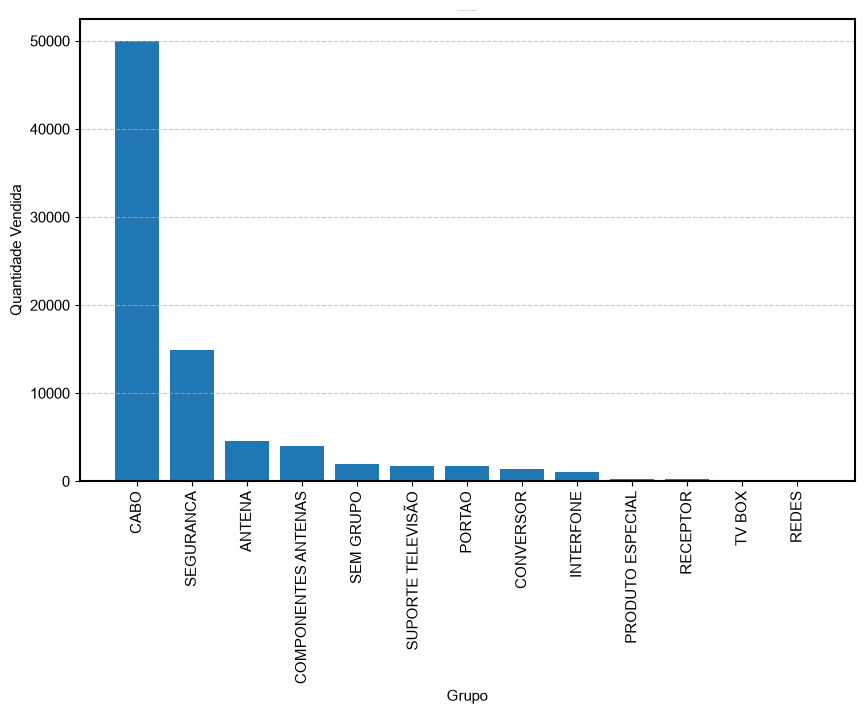

In [18]:
quantidade_vendida = banco_int.groupby('grupo')['quantidade'].sum().sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(quantidade_vendida.index, quantidade_vendida.values)
plt.title('quantity sold by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=90)
plt.ylabel('quantity sold')
plt.show()

cable parece be a group that can be considerado a *outlier* estrutural, however, must-if levar in consideração that suthe sales are legitimate. the important is note that the group cable possui a forma diferente of revenue, because has little value aggregated and is sold in quantities high.

also is possible note that the groups product ESPECIAL, receiver, TV BOX and REDES possuem few records, the that dificulta a analysis more profunda.

### number of sales by group

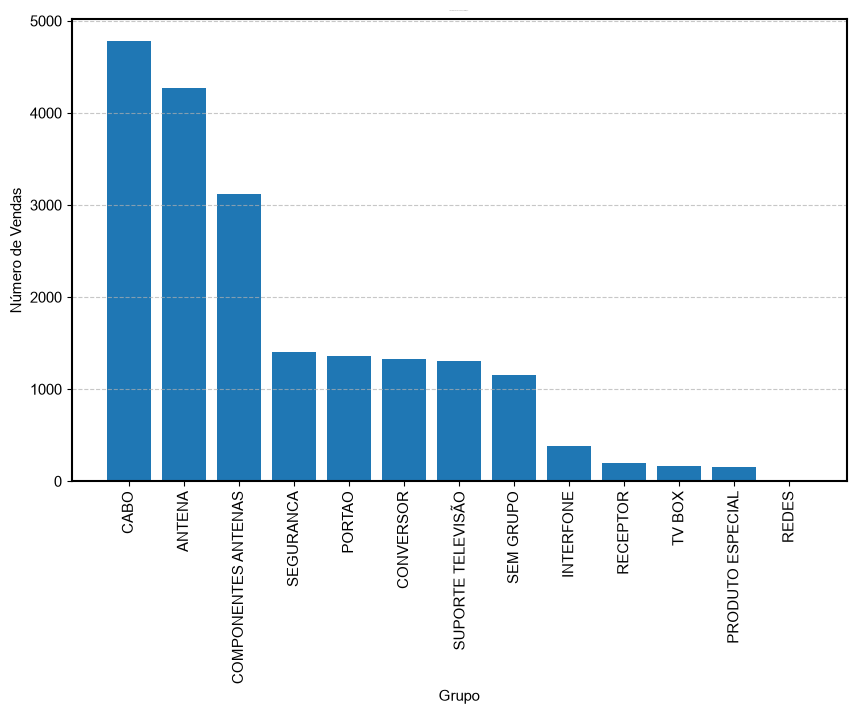

In [19]:
numero_vendas = banco_int.groupby('grupo').size().sort_values(ascending=False)

plt.figure(figsize=(10,6))
plt.bar(numero_vendas.index, numero_vendas.values)
plt.title('number of sales by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=90)
plt.ylabel('number of sales')
plt.show()

is important note that the group without group possui a quantity relativamente significativa of sales, it is useful understand which types of products ele representa.

### analysis of: without group, TV BOX, REDES, product ESPECIAL and receiver

In [20]:
banco_int.loc[banco_int['grupo'] == 'without group']

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
57,74,RX 4300 3 EM 1,350.0,1.0,350.0,2017-02-21,SEM GRUPO
114,84,RX 2200 VISIONTEC,270.0,1.0,270.0,2017-03-01,SEM GRUPO
117,84,RX 2200 VISIONTEC,270.0,1.0,270.0,2017-03-01,SEM GRUPO
136,84,RX 2200 VISIONTEC,230.0,1.0,230.0,2017-03-02,SEM GRUPO
144,37,RX ANALOGICO VT1000,180.0,1.0,180.0,2017-03-03,SEM GRUPO
...,...,...,...,...,...,...,...
19581,654,CAIXA ORGANIZADORA CFTV,13.5,4.0,54.0,2025-08-12,SEM GRUPO
19582,372,CONTROLE INTELBRAS,55.0,1.0,55.0,2025-08-12,SEM GRUPO
19585,591,"CONTROLE REMOTO TOK 433,92MHZ CRS",38.0,2.0,76.0,2025-08-13,SEM GRUPO
19588,407,BATERIA DE LITIO 3V CR 2032,8.0,1.0,8.0,2025-08-13,SEM GRUPO


In [21]:
banco_int[banco_int['grupo'] == 'without group'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
MINI REPETIDOR DE SINAL CELULAR AQUARIO 60,10,10.0,16105.0
MATERIAL EXTRA,69,69.0,11337.0
CENTRAL CERCA WIFI,23,23.0,11030.0
RX TV HD OI,5,26.0,9800.0
RX 2200 VISIONTEC,37,40.0,9435.0
...,...,...,...
"ESTRELINHA FIXA 1""",1,1.0,8.0
"IMA 8MMX13,6MMX23MM",1,2.0,7.0
EMENDA HDMI,1,1.0,7.0


the group without group possui high cardinalidade, because representa a group where not there were conhecimento sobre which era the type of product sold. keep ele in the dataset of date can support the understanding of the revenue global, mas atrapalha a analysis by group.

In [22]:
banco_int.loc[banco_int['grupo'] == 'TV BOX']

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
6107,334,TV BOX,150.0,2.0,300.0,2019-09-02,TV BOX
6117,334,TV BOX,150.0,1.0,150.0,2019-09-02,TV BOX
6151,334,TV BOX,150.0,1.0,150.0,2019-09-25,TV BOX
6162,334,TV BOX,150.0,1.0,150.0,2019-09-25,TV BOX
6180,334,TV BOX,150.0,1.0,150.0,2019-09-25,TV BOX
...,...,...,...,...,...,...,...
18036,601,CONTROLE TV BOX,50.0,1.0,50.0,2025-01-10,TV BOX
18097,601,CONTROLE TV BOX,40.0,1.0,40.0,2025-01-17,TV BOX
18604,601,CONTROLE TV BOX,40.0,1.0,40.0,2025-03-31,TV BOX
18803,601,CONTROLE TV BOX,40.0,1.0,40.0,2025-04-25,TV BOX


In [23]:
banco_int[banco_int['grupo'] == 'TV BOX'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
TV BOX,139,152.0,43033.0
CONTROLE TV BOX,19,19.0,755.0
ASSINATURA TV BOX,9,13.0,325.0
FONTE TV BOX 5V,1,1.0,40.0
MENSALIDADE TV BOX,1,1.0,30.0


the group TV BOX possui sales legitimate and can support a understand the revenue of the company, also of be a type específico of sales.

In [24]:
banco_int.loc[banco_int['grupo'] == 'product ESPECIAL']

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
176,0,INSTALAÇÃO SISTEMA DIGITAL,55.0,1.0,55.0,2017-03-06,PRODUTO ESPECIAL
1042,0,MISRTS,557.0,1.0,557.0,2017-06-19,PRODUTO ESPECIAL
1043,0,MENSALIDADE RIO OESTE B,600.0,1.0,600.0,2017-06-19,PRODUTO ESPECIAL
1044,0,COND ED ARNALDO BITENCURT,780.0,1.0,780.0,2017-06-19,PRODUTO ESPECIAL
1046,0,NEY IMOBILIARIA,650.0,1.0,650.0,2017-06-19,PRODUTO ESPECIAL
...,...,...,...,...,...,...,...
18596,0,GRADE DE PROTEÇÃO,50.0,1.0,50.0,2025-03-25,PRODUTO ESPECIAL
18597,0,CARTÃO DE MEMORIA,55.0,6.0,330.0,2025-03-25,PRODUTO ESPECIAL
18625,0,MATERIAL ELETRICO,100.0,1.0,100.0,2025-04-02,PRODUTO ESPECIAL
19121,0,BOTAO,30.0,1.0,30.0,2025-06-04,PRODUTO ESPECIAL


In [25]:
banco_int[banco_int['grupo'] == 'product ESPECIAL'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
PAGAMENTO 1 PARCELA,1,1.0,7536.0
DUOSAT,4,7.0,4120.0
MATERIAL EXTRA,8,8.0,1719.0
MO AGO,1,1.0,1540.0
ULTIMA PARCELA,1,1.0,1500.0
...,...,...,...
CABO DE FORÇA,1,1.0,10.0
ENTREGA,1,1.0,10.0
SUP FIXO 1*5,1,1.0,10.0


the group product ESPECIAL possui high cardinalidade and pouca concordância with which the type of product sold. Ele is similar to the without group and can prejudicar the analyses entre groups.

In [26]:
banco_int.loc[banco_int['grupo'] == 'REDES']

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
13907,637,SWITCH 8 P,100.0,1.0,100.0,2023-01-05,REDES
14346,593,ROTEADOR WIRELESS ACTION RF1200 4750075,250.0,1.0,250.0,2023-03-21,REDES
18722,637,SWITCH 8 P,100.0,1.0,100.0,2025-04-14,REDES
18723,472,ROTEADOR WIRELESS W5 - 1200F,300.0,1.0,300.0,2025-04-14,REDES
19085,637,SWITCH 8 P,280.0,1.0,280.0,2025-06-02,REDES


the group REDES possui only cinco records, the that leva a crer a presence of products atrelados to the este group mas that are espalhados in groups distintos. Novamente, ele só serviria for melhorar the understanding of the revenue global.

In [27]:
banco_int.loc[banco_int['grupo'] == 'RECEPTOR']

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
1832,220,RECEPTOR ANADIGI ELSYS,280.0,1.0,280.0,2017-10-06,RECEPTOR
1878,220,RECEPTOR ANADIGI ELSYS,280.0,1.0,280.0,2017-10-14,RECEPTOR
2144,220,RECEPTOR ANADIGI ELSYS,280.0,1.0,280.0,2017-11-28,RECEPTOR
2471,253,RECEPTOR DE SINAL DE TV VIA SATELITE MODELO SU...,350.0,1.0,350.0,2018-01-25,RECEPTOR
3068,261,RECEPTOR DIGITAL ULTRA BOX,560.0,1.0,560.0,2018-03-29,RECEPTOR
...,...,...,...,...,...,...,...
19386,729,RECEPTOR DE SINAL MIDIABOX B7,250.0,1.0,250.0,2025-07-10,RECEPTOR
19407,309,RECEPTOR CENTURY MIDIA BOX,250.0,1.0,250.0,2025-07-16,RECEPTOR
19461,729,RECEPTOR DE SINAL MIDIABOX B7,250.0,1.0,250.0,2025-07-23,RECEPTOR
19487,729,RECEPTOR DE SINAL MIDIABOX B7,250.0,1.0,250.0,2025-07-28,RECEPTOR


In [28]:
banco_int[banco_int['grupo'] == 'RECEPTOR'].groupby('descricao').agg(
        vendas=('descricao','size'),
        quantidade=('quantidade','sum'),
        faturamento=('valor_total','sum')
    ).sort_values('faturamento', ascending=False)

,vendas,quantidade,faturamento
descricao,,,
RECEPTOR SATMAX PLUS,47,65.0,29452.0
RECEPTOR SAT MAX,29,37.0,15724.0
RECEPTOR CENTURY MIDIA BOX,27,37.0,8885.0
RECEPTOR DIGITAL ULTRA BOX,25,25.0,8335.0
RECEPTOR DE SATELITE PARA RECEPCAO DE SINAL,5,20.0,7880.0
RECEPTOR SAT HD BEDINSAT,14,16.0,5710.0
RECEPTOR VIVENSIS,17,22.0,5663.0
RECEPTOR DE SINAL DIGITAL OITV,1,10.0,4500.0
RECEPTOR DE SINAL DE TV VIA SATELITE MODELO SUBST TRIBUTARIA CFE. DEC. 53511/08 ART 313 Y DEC,7,9.0,3412.0


sales legitimate in the group receiver

### revenue by group

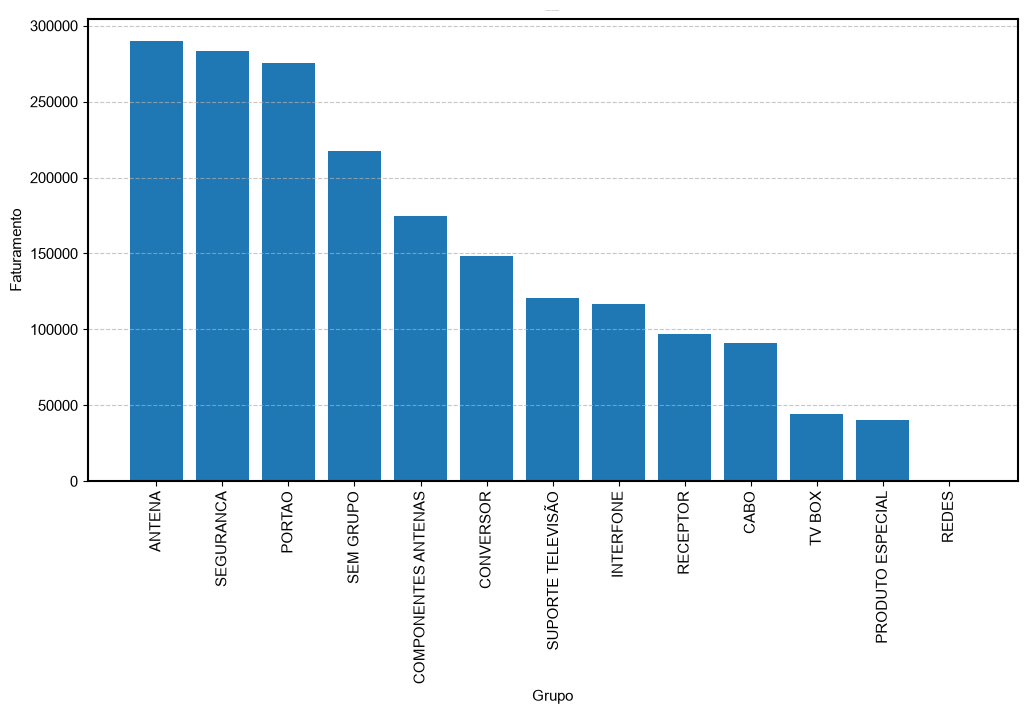

In [29]:
faturamento_por_grupo = banco_int.groupby('grupo')['valor_total'].sum().sort_values(ascending=False)

plt.figure(figsize=(12,6))
plt.bar(faturamento_por_grupo.index, faturamento_por_grupo.values)
plt.title('revenue by group')
plt.xlabel('Grupo')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=90)
plt.ylabel('Faturamento')
plt.show()

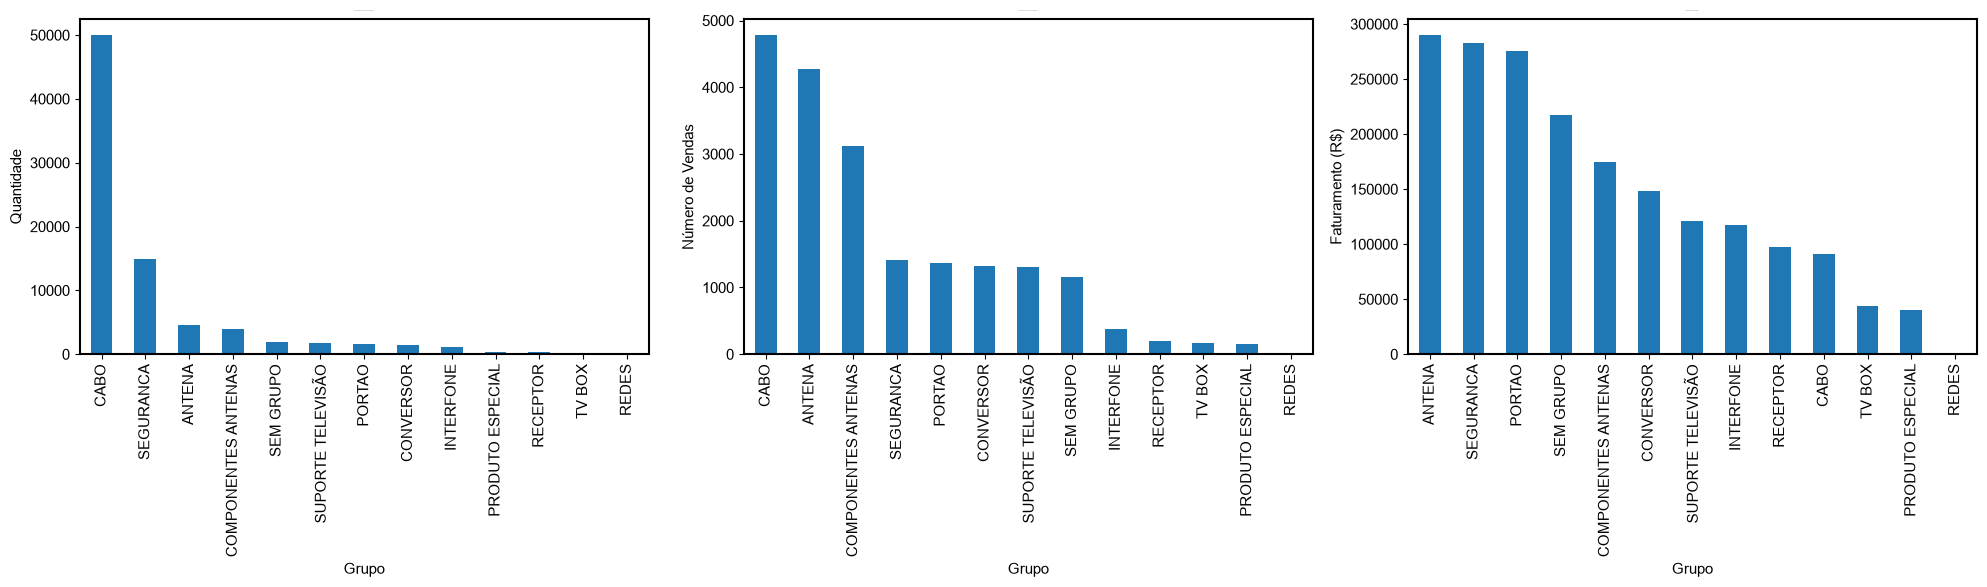

In [30]:
# Criando the 3 gráficos in a mesma linha
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Gráfico 1 - quantity sold
quantidade_vendida.plot(
    kind='bar',
    ax=axes[0]
)
axes[0].set_title('quantity sold by group')
axes[0].set_xlabel('Grupo')
axes[0].set_ylabel('Quantidade')
axes[0].tick_params(axis='x', rotation=90)

# Gráfico 2 - number of sales
numero_vendas.plot(
    kind='bar',
    ax=axes[1]
)
axes[1].set_title('number of sales by group')
axes[1].set_xlabel('Grupo')
axes[1].set_ylabel('number of sales')
axes[1].tick_params(axis='x', rotation=90)

# Gráfico 3 - revenue
faturamento_por_grupo.plot(
    kind='bar',
    ax=axes[2]
)
axes[2].set_title('revenue by group')
axes[2].set_xlabel('Grupo')
axes[2].set_ylabel('revenue (R$)')
axes[2].tick_params(axis='x', rotation=90)

# Ajusta the espaçamento
plt.tight_layout()

plt.show()

### analysis conjunta

a comparação of the três métricas permite identificar different perfis of groups of products:

- **cable:** apresenta the higher volume of units vendidas and the higher number of sales, mas possui revenue relativamente low. this caracteriza a group of **high volume and low value unitário médio**.
- **antenna:** apresenta elevado number of sales and ocupa a first position in revenue, indicando a combination favorável entre **frequência of sales and value aggregated of the products**.
- **security:** apresenta high quantity of units vendidas and elevado revenue, mas a number of sales relativamente lower. this sugere **higher quantity mean of itens by sale and higher value aggregated**.
- **gate:** apresenta a number of sales intermediário, mas is entre the groups of higher revenue, indicando **elevado value médio by sale**.
- **components antennas:** possui a quantity relevante of sales, mas seu revenue is inferior to the of the principais groups, indicando a **value médio by sale more low**.
- **TV BOX** and **product ESPECIAL** apresentam lower participação tanto in number of sales quanto in revenue, embora the segundo apresente a revenue superior to the expected in relation to to the seu volume of sales.
- **REDES** apresenta participação very low in the três métricas, indicando low representatividade comercial in the set analyzed.
- **without group** apresenta a high value aggregated, because possui a number of sales médio, mas a boa colocação in revenue. however, it is necessary understand sua high cardinalidade.

Após all the analyses and understanding of the negócio, we notice that the groups without group, product ESPECIAL, TV BOX and REDES possuem high carinalidade and problemas associados to the descriptions of the products. Apesar destes groups contribuirem positivamente for a building of the métrica of revenue monthly of the company, eles trazem aspectos negative quanto to the understanding of the negócio and, mainly, understanding of the seasonality; therefore, eles will be removed of the set of date.

In [31]:
banco_int.head()

,id_produto,descricao,valor_unitario,quantidade,valor_total,data_venda,grupo
0,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
1,40,CONECTOR ANILHA RG06,1.0,1.0,1.0,2017-02-14,CABO
2,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR
3,25,ANT. UHF GRANDE,50.0,1.0,50.0,2017-02-14,ANTENA
4,65,CONVERSOR DIGITAL BEDIN,110.0,1.0,110.0,2017-02-14,CONVERSOR


In [32]:
banco_int = banco_int[~banco_int['grupo'].isin(['without group', 'product ESPECIAL', 'TV BOX', 'REDES'])]

In [33]:
# number of records restantes in the dataset of date
print(f"O número de registros restantes no banco de dados é: {banco_int.shape[0]}")

O número de registros restantes no banco de dados é: 18157


### revenue by group by year

In [34]:
# Modificando a coluna of date for the formato datetime
banco_int['data_venda'] = pd.to_datetime(
    banco_int['data_venda'],
    errors='coerce' # Converte values not convertíveis for NaT
)

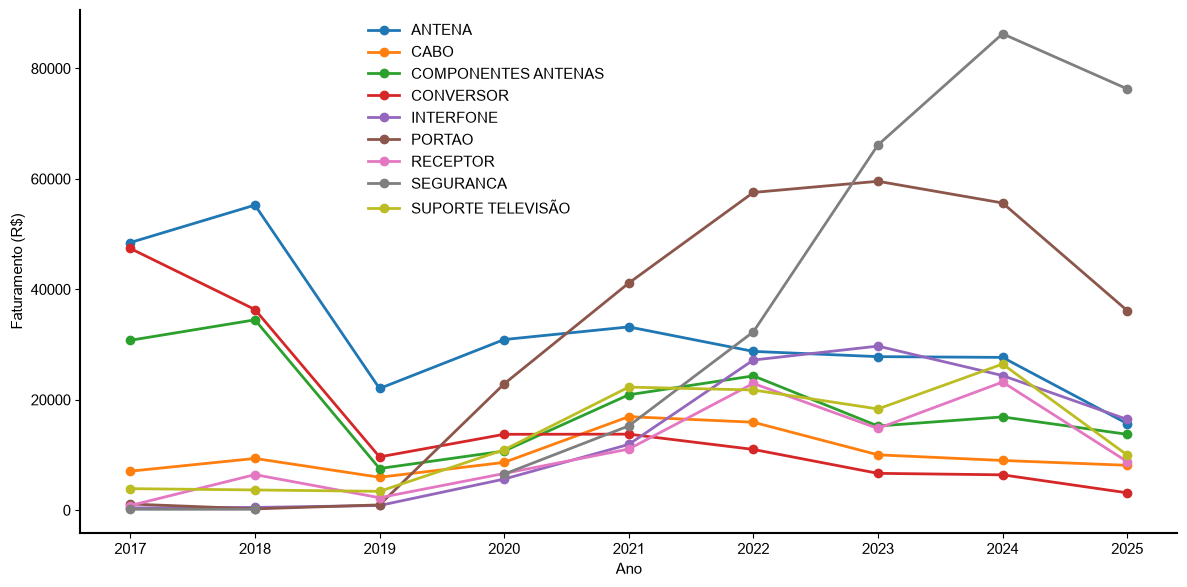

In [35]:
faturamento_grupo_ano = banco_int.groupby([banco_int['data_venda'].dt.year,'grupo'])['valor_total'].sum().reset_index()

faturamento_grupo_ano.columns = ['ano','grupo','faturamento']

pivot = faturamento_grupo_ano.pivot(
    index='ano',
    columns='grupo',
    values='faturamento'
)

fig, ax = plt.subplots(figsize=(12, 6))

pivot.plot(
    ax=ax,
    marker='o',
    linewidth=2
)

# titles of the axes
ax.set_xlabel("Ano", fontsize=11, fontname="Arial")
ax.set_ylabel("revenue (R$)", fontsize=11, fontname="Arial")

# Remove the title
ax.set_title("")

# Remove a grid
ax.grid(False)

# Remove bordas superior and direita
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# keeps only the axes principais
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)

ax.spines["left"].set_color("black")
ax.spines["bottom"].set_color("black")

# legend
ax.legend(
    title=None,
    bbox_to_anchor=(0.25, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()

for concluir this analysis of the groups of products vendidos nesta company, is possible notice that there are a high cardinalidade in the products, the that resultaria in limitações for a creation of the models preditivos pela high variability of the séries individuais; also disso, the groups possuem different quantities of records, some less that the outros, dificultando a modeling of the séries temporais indivuais.

### correlation entre the sales of different groups

In [36]:
# Série temporal monthly of revenue by group

faturamento_grupos = (
banco_int
    .groupby([
        banco_int['data_venda'].dt.to_period('M'), 'grupo'
    ])['valor_total'].sum().unstack(fill_value=0)
)
# unstack() cria a "table dynamics" a partir of the result of the groupby, where the index is a date of sale monthly 
# and the columns are the groups, with the values being the revenue total for each group in each month.    
# Ele is used for transformar the groups in columns, and fill_value=0 fills the values missing with zero.

faturamento_grupos.index = (
    faturamento_grupos.index.to_timestamp()
)

faturamento_grupos.head()


grupo,ANTENA,CABO,COMPONENTES ANTENAS,CONVERSOR,INTERFONE,PORTAO,RECEPTOR,SEGURANCA,SUPORTE TELEVISÃO
data_venda,,,,,,,,,
2017-02-01,1855.0,208.0,785.0,2380.0,0.0,120.0,0.0,0.0,105.0
2017-03-01,6337.0,817.0,2359.0,17785.0,0.0,40.0,0.0,0.0,205.0
2017-04-01,5770.0,706.0,1058.0,2620.0,0.0,40.0,0.0,0.0,180.0
2017-05-01,4805.0,688.0,1651.0,4295.0,0.0,5.0,0.0,0.0,445.0
2017-06-01,3752.0,372.0,784.0,4660.0,240.0,0.0,0.0,0.0,405.0


<Axes: xlabel='grupo', ylabel='grupo'>

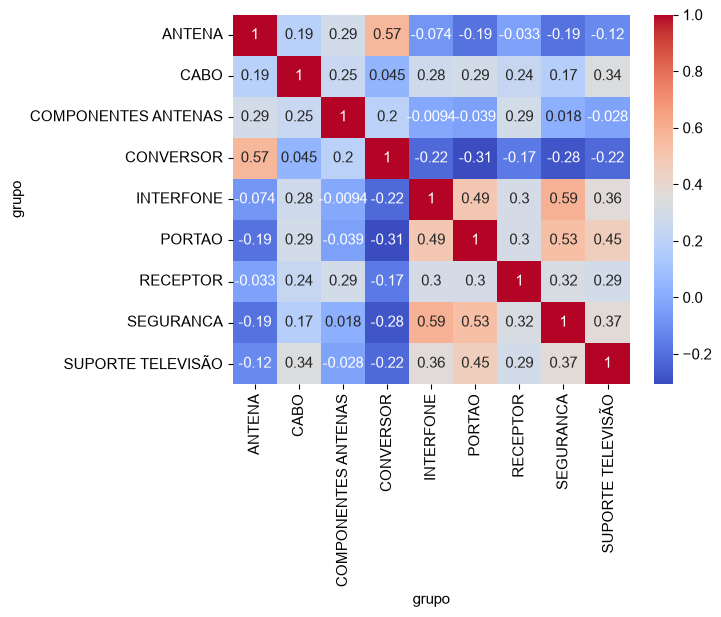

In [37]:
# correlation entre sales monthly of the groups

corr = faturamento_grupos.corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

some considerações and conclusões can be feitas:
1) the sales of the groups antenna, cable, components antennas and converter are the more correlacionadas, since these products are vendidos in set in the maioria of the vezes. Este fato can be confirmado pelo gráfico of revenue by group throughout of the years, the which shows that the trends of growth and decline of revenue destes respectivos groups if acompanham throughout of the years.
2) Adicionalmente, podemos note that the groups SEGURANCA, intercom and PORTAO also possuem high correlation. Inclusive, the large growth of the sales destes groups of products if deu mainly in the year of 2020, coincidindo with the start of the pandemia of COVID-19.

## Ticket-Médio by sale in group

In [44]:
resumo_grupos = banco.groupby('grupo').agg(vendas=('grupo', 'size'), quantidade=('quantidade', 'sum'), 
                                           faturamento=('valor_total', 'sum')).sort_values('faturamento', ascending=False)


resumo_grupos

,vendas,quantidade,faturamento
grupo,,,
ANTENA,4270,4616.0,289776.0
SEGURANCA,1406,14938.0,283143.0
PORTAO,1363,1678.0,275221.0
SEM GRUPO,1150,1936.0,217568.0
COMPONENTES ANTENAS,3122,3944.0,174592.0
CONVERSOR,1327,1444.0,148119.0
SUPORTE TELEVISÃO,1309,1749.0,120757.0
INTERFONE,382,1103.0,117026.0
RECEPTOR,199,274.0,97007.0


In [45]:
resumo_grupos['ticket_medio'] = resumo_grupos['faturamento'] / resumo_grupos['vendas']

resumo_grupos.sort_values('ticket_medio', ascending=False)

,vendas,quantidade,faturamento,ticket_medio
grupo,,,,
RECEPTOR,199,274.0,97007.0,487.472362
INTERFONE,382,1103.0,117026.0,306.350785
PRODUTO ESPECIAL,153,303.0,40184.0,262.640523
TV BOX,169,186.0,44183.0,261.437870
REDES,5,5.0,1030.0,206.000000
PORTAO,1363,1678.0,275221.0,201.922964
SEGURANCA,1406,14938.0,283143.0,201.381935
SEM GRUPO,1150,1936.0,217568.0,189.189565
CONVERSOR,1327,1444.0,148119.0,111.619442


* here we can see that antenna is a group equilibrado, since possui a number of sales and quantity vendidas próximas, this shows that in a sale vende-if pelo less a antenna for este group.

* Outro aspecto interesting is the number of *sales* of the groups components antennas and cable, the which are complementary to the group antenna, since for perform a instalção, usas-if itens destes outros dois groups.

* however, cable is a group estruturalmente complex for forecasts, since seu revenue is relativamente low in relation to to the outros groups mas still thus has 3x more quantity sold of the that the segundo group more sold (security), the that demonstra that a sale ocorre majoritariamente by metragem and with low value aggregated. therefore, este dado serve only the complemento to the sales of antenna, for example.

* Similarmente, the group SEGURANCA apresenta few sales mas with large quantity and a high revenue, the that demonstra be sale of itens based in metragem and many quantities (cables of high tensão, hastes of about, cameras of security, entre outros); however, still thus is a group with high revenue (the segundo higher), being necessary a analysis more profunda sobre the products agregados to the group.

* also disso, groups the intercom, receiver, converter, PORTAO and bracket television if show interesting and relativamente equilibrados and bons for serem analisados from seasonality. 
    1) the group PORTAO and intercom possuem less sales that SEGURANCA, mas still thus possuem a high revenue, the that indica a high ticket médio. 
    2) the group converter possui a equilíbrio entre sales and quantities vendidas, with a revenue médio, the that demonstra be a variable boa for analysis.
    3) Similarmente, the group bracket television it is useful of be analyzed based in seasonality, being a bom candidato for understand sua seasonality and oferecer more demand in certos periods. 

* observing-if the ticket médio, podemos note that the itens with more relevance in relation to to the revenue of the company are receiver, intercom, SEGURANCA and PORTAO.

* here it is useful note that, apesar of the groups antenna, COMPONENTE antenna and cable participarem of large quantities of sale, still thus not if show the the "carro chefe" of the company.

* the fato of the ticket médio of the PORTAO be praticamente igual to the of the group SEGURANCA sugere that itens of the group PORTAO possuem values more high and, possivelmente, are vendidos junto to the itens of SEGURANCA

In [38]:
def plot_faturamento_anual(df, grupos, titulo):
    df_filtrado = df[df["grupo"].isin(grupos)].copy()

    anual = (
        df_filtrado
        .groupby([df_filtrado["data_venda"].dt.year, "grupo"])["valor_total"]
        .sum()
        .reset_index()
        .pivot(index="data_venda", columns="grupo", values="valor_total")
    )

    fig, ax = plt.subplots(figsize=(12, 6))
    anual.plot(ax=ax, marker="o", linewidth=2)

    ax.set_title(titulo)
    ax.set_xlabel("Ano")
    ax.set_ylabel("revenue (R$)")
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(title=None, frameon=False)
    plt.tight_layout()
    plt.show()

#### Série of revenue annual: intercom, PORTAO, SEGURANCA

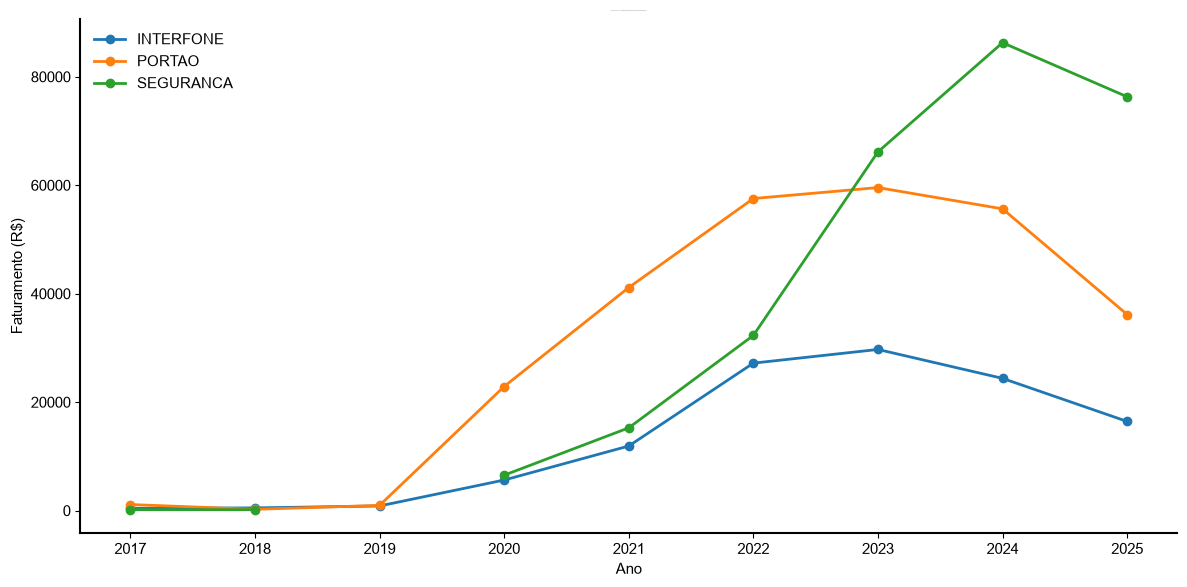

In [39]:
# intercom, PORTAO and SEGURANCA
plot_faturamento_anual(
    banco_int,
    ["INTERFONE", "PORTAO", "SEGURANCA"],
    "revenue annual: intercom, PORTAO and SEGURANCA"
)

#### Série of revenue annual: antenna, components antenna and cable

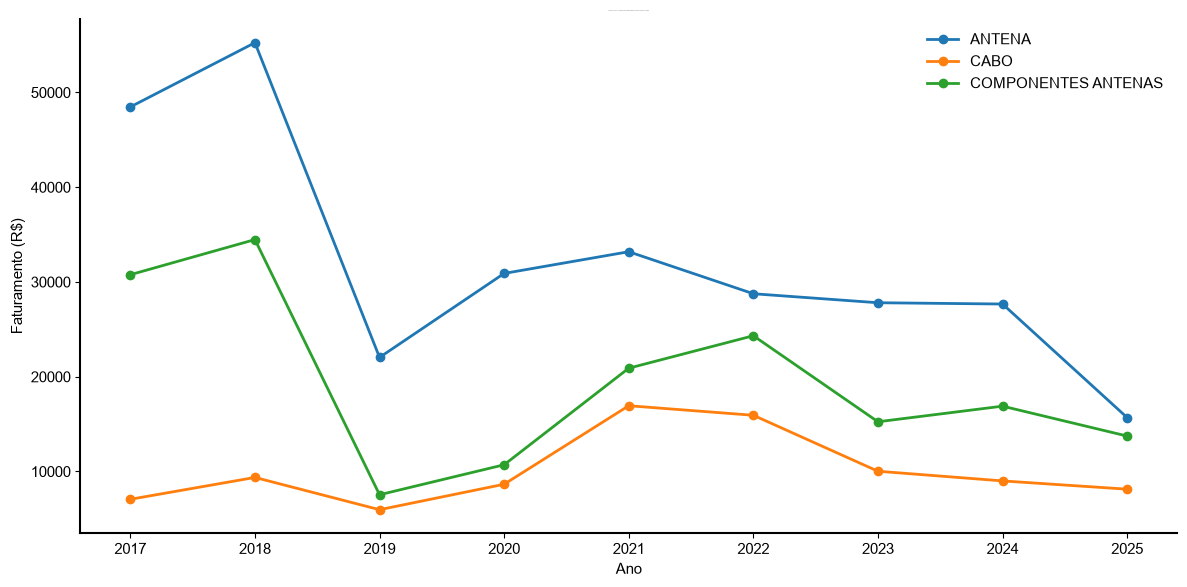

In [40]:
plot_faturamento_anual(
    banco_int,
    ["ANTENA", "components antennas", "CABO"],
    "revenue annual: antenna, components antennas and cable"
)

Esta analysis permite understand more the negócio desta small company:
1) in the year iniciais, the principal foco of the company era installations of antennas, with foco in sale of products voltadas to the televisões num geral; however, the sales of itens of the market of security começaram a grow in 2019, ganhando a aumento expressivo in 2020 and crescendo até the year of 2024.

2) a decline brusca in the year of 2025 was relatado pela company by be a year with mudanças estruturais of the dataset of date of the company and, by this, must-if analyze with cuidado este period of the séries temporais.

## date Intermediários

In [42]:
banco_int.to_csv(
    "../data/interm/data_2.csv",
    index=False
)

# Conclusão

Após the analyses here realizadas, some ideias, hypotheses and considerações are feitas:

1) a high variability of the type of item sold in each market of product dificulta a analysis of the revenue individual; however, fica the a ideia of projeto futuro analyze these groups separadamente for understand possible efeitos of seasonality.

2) the fato of some groups possuirem more values agregados for different itens, this is, there are groups that with only a item equivale to the revenue of diversos itens of outro group. Este result evidencia a dificultade of the comparação direta entre the different groups, sugerindo that a analysis of the revenue monthly total whether more viável neste projeto.

3) analyze cuidadosamente the date of the série temporal in the year of 2025, because there are date missing by possible problemas estruturais of the dataset of date of the company.